# TrafficFlowBench data exploration

This notebook gives a visual overview of one released **training** panel: its network topology, detector time series, traffic regimes, masking patterns, and Task 2 forecast windows. It uses Matplotlib for figures and Polars for reading the partitioned Parquet files. If Matplotlib is missing from your environment, install it with `%pip install matplotlib` before running the notebook.

The default panel is `D12_I5_N`. Change the configuration below to explore another panel. Evaluation splits are read only for published Task 2 window metadata and for a check of whether masked measurements are visible at T+30; the notebook does not load unmasked evaluation observations or evaluation answers.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# Keep the first pass small and reproducible; use dates from the training split.
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "kaggle_public").exists():
    REPO_ROOT = REPO_ROOT.parent
DATA_ROOT = REPO_ROOT / "kaggle_public"
PANEL = "D12_I5_N"
SPLIT = "train"
EXAMPLE_DATE = "2030-06-01"
QUEUE_SPEED_FRACTION = 0.60

plt.rcParams.update({"figure.figsize": (14, 5), "axes.grid": True, "grid.alpha": 0.25})
assert DATA_ROOT.exists(), f"Could not find release data at {DATA_ROOT}"


## Load panel metadata and a single day

The topology file supplies a consistent upstream-to-downstream link order. The daily Parquet partitions keep the time-series read bounded; edit `EXAMPLE_DATE` to inspect another training day.


In [2]:
# Load compact network metadata, then filter the selected day's sensor records.
panel_root = DATA_ROOT / "corridors" / PANEL
train_root = panel_root / SPLIT
network = pl.read_csv(panel_root / "network" / "lwr_mainline_topology.csv").sort("order_index")
links = network.select("mainline_link_id", "order_index", "free_flow_speed_kmh", "length_km", "has_sensor")

mainline_glob = str(train_root / "mainline_states" / "**" / "*.parquet")
day = (
    pl.scan_parquet(mainline_glob, hive_partitioning=True)
    .filter(pl.col("date") == EXAMPLE_DATE)
    .collect()
    .join(links, left_on="link_id", right_on="mainline_link_id", how="left")
    .sort(["timestamp", "order_index"])
)
print(f"{PANEL} · {EXAMPLE_DATE}: {day.height:,} link-time rows, {day['link_id'].n_unique()} links")
print(day.select("timestamp", "link_id", "speed_kmh", "flow_vph", "occupancy", "is_observed").head())


D12_I5_N · 2030-06-01: 74,304 link-time rows, 258 links
shape: (5, 6)
┌──────────────────────┬─────────┬────────────┬─────────────┬───────────┬─────────────┐
│ timestamp            ┆ link_id ┆ speed_kmh  ┆ flow_vph    ┆ occupancy ┆ is_observed │
│ ---                  ┆ ---     ┆ ---        ┆ ---         ┆ ---       ┆ ---         │
│ str                  ┆ str     ┆ f64        ┆ f64         ┆ f64       ┆ i64         │
╞══════════════════════╪═════════╪════════════╪═════════════╪═══════════╪═════════════╡
│ 2030-06-01T00:00:00Z ┆ L5N-186 ┆ 114.168642 ┆ 1491.305707 ┆ 0.048971  ┆ 1           │
│ 2030-06-01T00:00:00Z ┆ L5N-182 ┆ 117.392456 ┆ 1451.195887 ┆ 0.049988  ┆ 1           │
│ 2030-06-01T00:00:00Z ┆ L5N-177 ┆ 116.75818  ┆ 1475.571332 ┆ 0.045062  ┆ 1           │
│ 2030-06-01T00:00:00Z ┆ L5N-176 ┆ 118.066394 ┆ 1464.648797 ┆ 0.050164  ┆ 1           │
│ 2030-06-01T00:00:00Z ┆ L5N-017 ┆ 115.422167 ┆ 1496.251378 ┆ 0.035805  ┆ 1           │
└──────────────────────┴─────────┴────────────┴───

## 1. Mainline and ramp topology

The release provides link order and ramp attachments, but not geographic
coordinates. This is a topology schematic, not a map: mainline links follow the
published upstream-to-downstream order, and each colored branch arrow marks a
ramp connected to a mainline link. Use it to orient the link order used in the
traffic charts below.


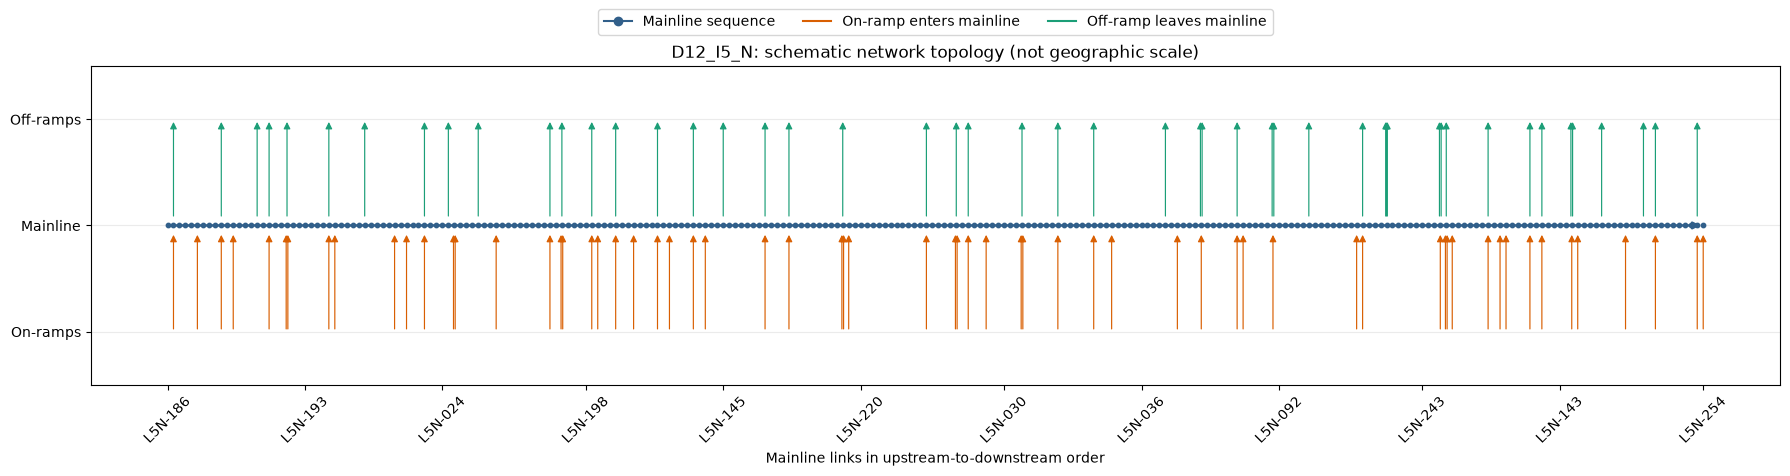

D12_I5_N: 258 ordered mainline links, 63 on-ramps, and 49 off-ramps


In [3]:
# Draw the published mainline sequence and its attached on- and off-ramps.
from matplotlib.lines import Line2D

topology_rows = network.sort("order_index").to_dicts()
mainline_link_count = len(topology_rows)
mainline_positions = np.arange(mainline_link_count, dtype=float)
mainline_y = 0.0
ramp_distance = 0.48
ramp_offset = 0.14

fig, ax = plt.subplots(figsize=(18, 5))
ax.annotate(
    "",
    xy=(mainline_link_count - 1, mainline_y),
    xytext=(0, mainline_y),
    arrowprops={"arrowstyle": "-|>", "color": "#315f8a", "linewidth": 1.8},
)
ax.scatter(
    mainline_positions,
    np.full(mainline_link_count, mainline_y),
    s=10,
    color="#315f8a",
    zorder=3,
)

# Draw one branch for each ramp identifier, offsetting co-located ramps slightly.
on_ramp_count = 0
off_ramp_count = 0
for position, row in enumerate(topology_rows):
    for ramp_field, is_on_ramp, color in (
        ("on_ramp_link_ids", True, "#d95f02"),
        ("off_ramp_link_ids", False, "#1b9e77"),
    ):
        ramp_ids = [
            ramp_id.strip()
            for ramp_id in (row[ramp_field] or "").split(";")
            if ramp_id.strip()
        ]
        if not ramp_ids:
            continue
        if len(ramp_ids) == 1:
            branch_offsets = [0.0]
        else:
            branch_offsets = np.linspace(-ramp_offset, ramp_offset, len(ramp_ids))
        for branch_offset in branch_offsets:
            branch_x = position + branch_offset
            if is_on_ramp:
                ax.annotate(
                    "",
                    xy=(branch_x, mainline_y - 0.03),
                    xytext=(branch_x, -ramp_distance),
                    arrowprops={"arrowstyle": "-|>", "color": color, "linewidth": 0.85},
                )
                on_ramp_count += 1
            else:
                ax.annotate(
                    "",
                    xy=(branch_x, ramp_distance),
                    xytext=(branch_x, mainline_y + 0.03),
                    arrowprops={"arrowstyle": "-|>", "color": color, "linewidth": 0.85},
                )
                off_ramp_count += 1

# Label a sample of links so the chart stays readable across long panels.
tick_positions = np.unique(
    np.linspace(0, mainline_link_count - 1, num=min(12, mainline_link_count), dtype=int)
)
ax.set_xticks(
    tick_positions,
    labels=[topology_rows[int(position)]["mainline_link_id"] for position in tick_positions],
)
ax.set_yticks(
    [ramp_distance, mainline_y, -ramp_distance],
    ["Off-ramps", "Mainline", "On-ramps"],
)
ax.set_ylim(-0.72, 0.72)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Mainline links in upstream-to-downstream order")
ax.set_title(f"{PANEL}: schematic network topology (not geographic scale)")
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[
        Line2D([0], [0], color="#315f8a", marker="o", label="Mainline sequence"),
        Line2D([0], [0], color="#d95f02", label="On-ramp enters mainline"),
        Line2D([0], [0], color="#1b9e77", label="Off-ramp leaves mainline"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.2),
    ncol=3,
)
fig.tight_layout()
plt.show()
print(
    f"{PANEL}: {mainline_link_count} ordered mainline links, "
    f"{on_ramp_count} on-ramps, and {off_ramp_count} off-ramps"
)

## 2. Corridor speed over time and space

Each row is a mainline link in topology order; each column is a five-minute timestamp. Queue-like slowdowns often show up as connected bands that move upstream or persist across links. This view uses the unmasked training series.


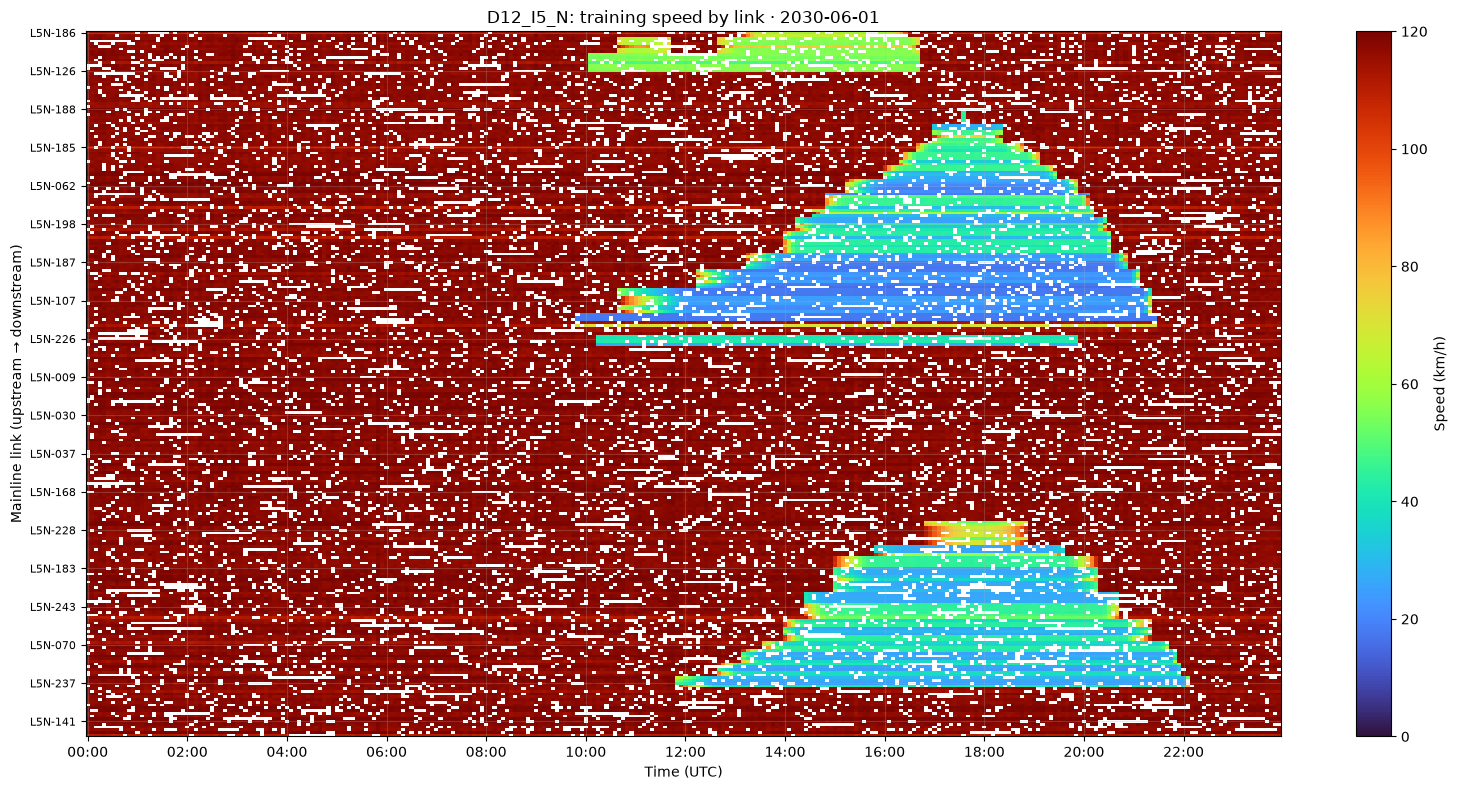

In [4]:
# Pivot the day's speeds into a link-by-time matrix for a space-time heatmap.
timestamps = day.get_column("timestamp").unique(maintain_order=True).to_list()
link_order = links.get_column("mainline_link_id").to_list()
speed_matrix = (
    day.pivot(on="timestamp", index="link_id", values="speed_kmh", aggregate_function="mean")
    .select("link_id", *timestamps)
    .sort("link_id")
)
speed_matrix = speed_matrix.join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id").sort("order_index")
speed_values = speed_matrix.select(timestamps).to_numpy()

fig, ax = plt.subplots(figsize=(16, 8))
image = ax.imshow(speed_values, aspect="auto", interpolation="nearest", cmap="turbo", vmin=0, vmax=120)
link_tick_positions = np.arange(0, len(link_order), max(1, len(link_order) // 18))
ax.set_yticks(link_tick_positions, labels=[link_order[i] for i in link_tick_positions], fontsize=8)
ax.set_xticks(np.arange(0, len(timestamps), 24), labels=[timestamps[i][11:16] for i in range(0, len(timestamps), 24)])
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Mainline link (upstream → downstream)")
ax.set_title(f"{PANEL}: training speed by link · {EXAMPLE_DATE}")
fig.colorbar(image, ax=ax, label="Speed (km/h)")
plt.tight_layout()
plt.show()


## 3. Speed versus flow

The speed-flow relationship helps reveal free-flow traffic, congestion, and detector variation. Points are colored by occupancy; sampling keeps the chart responsive for panels with many links.


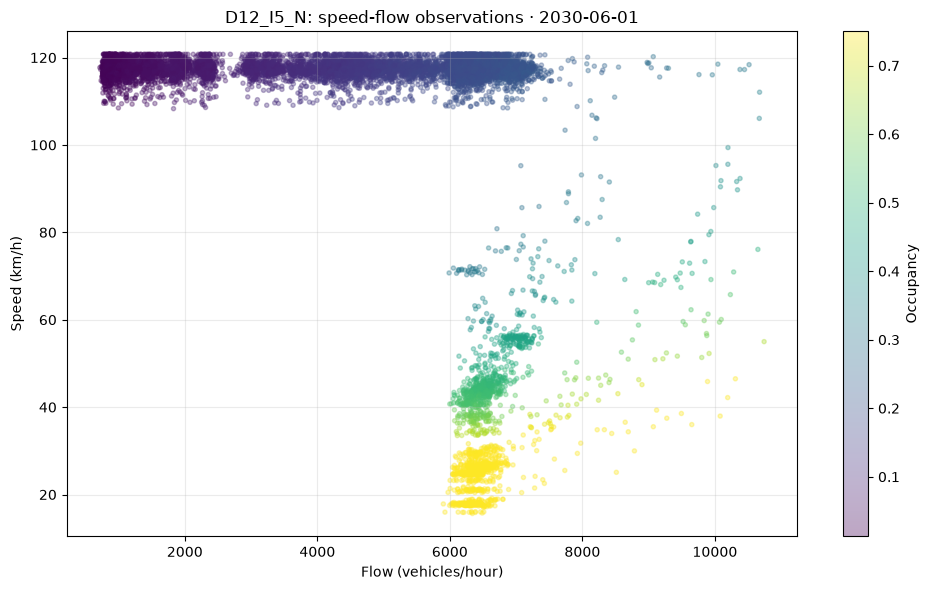

In [5]:
# Plot a deterministic sample so dense panels remain readable.
scatter_data = day.select("speed_kmh", "flow_vph", "occupancy").drop_nulls().sample(n=min(12000, day.height), seed=7)
fig, ax = plt.subplots(figsize=(10, 6))
points = ax.scatter(scatter_data["flow_vph"], scatter_data["speed_kmh"], c=scatter_data["occupancy"], s=9, alpha=0.35, cmap="viridis")
ax.set_xlabel("Flow (vehicles/hour)")
ax.set_ylabel("Speed (km/h)")
ax.set_title(f"{PANEL}: speed-flow observations · {EXAMPLE_DATE}")
fig.colorbar(points, ax=ax, label="Occupancy")
plt.tight_layout()
plt.show()


## 4. Masking and observation coverage

The masked release is the view a reconstruction model receives. This compares it with the corresponding unmasked training day, then plots where measurements were removed. The panel uses the same link and timestamp coordinates as the speed heatmap.


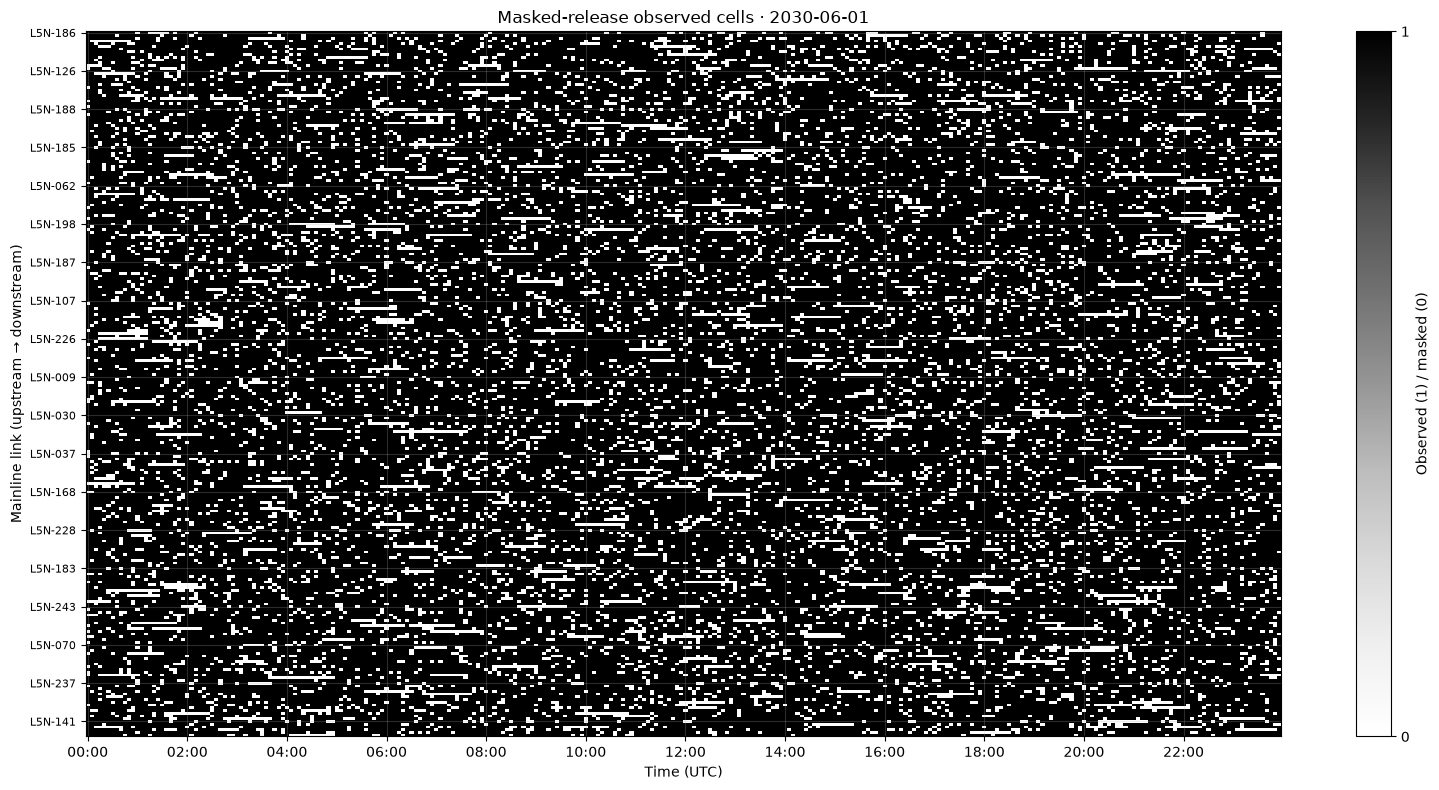

Observed fraction for this day: 83.6%


In [6]:
# Read the matching masked-day partition and build its observation-coverage matrix.
masked_glob = str(train_root / "mainline_states_masked" / "**" / "*.parquet")
masked_day = (
    pl.scan_parquet(masked_glob, hive_partitioning=True)
    .filter(pl.col("date") == EXAMPLE_DATE)
    .collect()
)
coverage = (
    masked_day.pivot(on="timestamp", index="link_id", values="is_observed", aggregate_function="max")
    .select("link_id", *timestamps)
    .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id")
    .sort("order_index")
    .select(timestamps)
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(16, 8))
image = ax.imshow(coverage, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
link_tick_positions = np.arange(0, len(link_order), max(1, len(link_order) // 18))
ax.set_yticks(link_tick_positions, labels=[link_order[i] for i in link_tick_positions], fontsize=8)
ax.set_xticks(np.arange(0, len(timestamps), 24), labels=[timestamps[i][11:16] for i in range(0, len(timestamps), 24)])
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Mainline link (upstream → downstream)")
ax.set_title(f"Masked-release observed cells · {EXAMPLE_DATE}")
fig.colorbar(image, ax=ax, ticks=[0, 1], label="Observed (1) / masked (0)")
plt.tight_layout()
plt.show()
print(f"Observed fraction for this day: {masked_day['is_observed'].mean():.1%}")


## 5. Task 2: inspect a forecast window

The window index identifies onset and ongoing queue examples, and the history file contains the 60 minutes available before each forecast origin. This chart shows one history heatmap and the following 30 minutes of **training labels**, obtained from the unmasked training data. A vertical divider marks forecast origin `T`.

This is for understanding the training examples. For a validation or private Task 2 forecast, only data timestamped at or before each window's `T` may be used.


In [7]:
# Select an example from the requested training date and load its 60-minute history.
window_index = pl.read_csv(DATA_ROOT / "task2" / PANEL / SPLIT / "window_index.csv")
example = window_index.filter(pl.col("date") == EXAMPLE_DATE).row(0, named=True)
window_id = example["window_id"]
history = (
    pl.read_parquet(DATA_ROOT / "task2" / PANEL / SPLIT / "window_history.parquet")
    .filter(pl.col("window_id") == window_id)
    .join(links, left_on="link_id", right_on="mainline_link_id", how="left")
)
origin = example["forecast_origin"]
forecast_start = example["forecast_start"]
forecast_end = example["forecast_end"]
label_rows = day.filter(pl.col("timestamp").is_between(pl.lit(forecast_start), pl.lit(forecast_end), closed="both"))
window_links = links.get_column("mainline_link_id").to_list()
window_times = sorted(history.get_column("timestamp").unique().to_list())
forecast_times = sorted(label_rows.get_column("timestamp").unique().to_list())


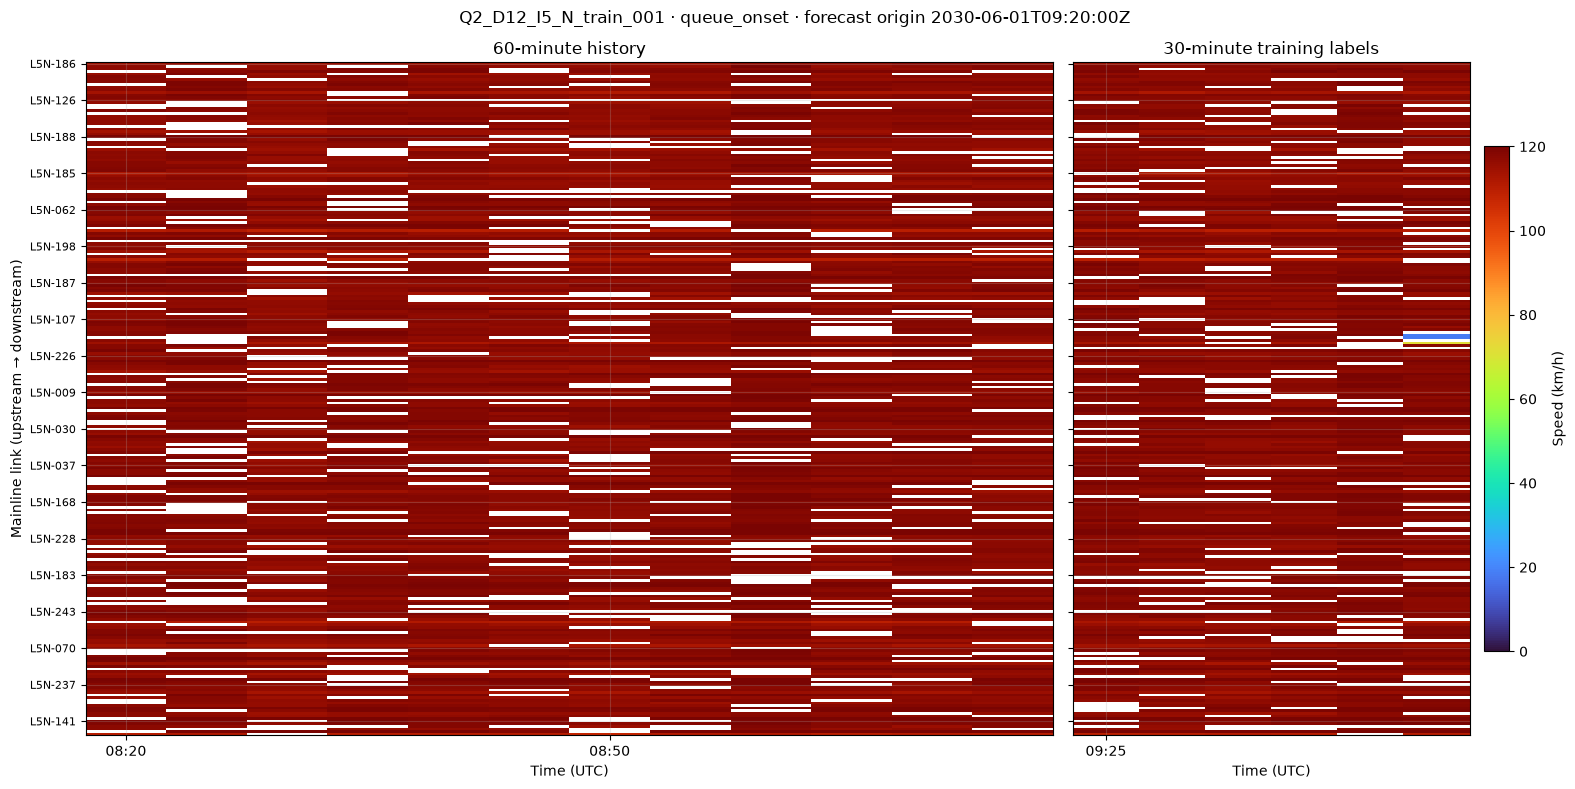

In [8]:
# Render history and the train-only future label period as separate panels.
def matrix_for(frame: pl.DataFrame, value: str, times: list[str]) -> np.ndarray:
    """Return a link-ordered matrix for the requested time series field.

    Args:
        frame: Rows containing `link_id`, `order_index`, timestamps, and values.
        value: Numeric column to display.
        times: Timestamp columns in display order.

    Returns:
        A matrix with one row per ordered mainline link and one column per timestamp.
    """
    pivoted = frame.pivot(on="timestamp", index="link_id", values=value, aggregate_function="mean")
    available_times = [timestamp for timestamp in times if timestamp in pivoted.columns]
    ordered = (
        pivoted.select("link_id", *available_times)
        .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id", how="right")
        .sort("order_index")
    )
    return ordered.select(available_times).to_numpy()

history_values = matrix_for(history, "speed_kmh", window_times)
label_values = matrix_for(label_rows, "speed_kmh", forecast_times)
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
for ax, values, times, title in zip(axes, (history_values, label_values), (window_times, forecast_times), ("60-minute history", "30-minute training labels")):
    plot = ax.imshow(values, aspect="auto", interpolation="nearest", cmap="turbo", vmin=0, vmax=120)
    ax.set_title(title)
    tick_positions = np.arange(0, len(times), 6)
    ax.set_xticks(tick_positions, labels=[times[i][11:16] for i in tick_positions])
    ax.set_xlabel("Time (UTC)")
window_tick_positions = np.arange(0, len(window_links), max(1, len(window_links) // 18))
axes[0].set_yticks(window_tick_positions, labels=[window_links[i] for i in window_tick_positions], fontsize=8)
axes[0].set_ylabel("Mainline link (upstream → downstream)")
fig.suptitle(f"{window_id} · {example['condition']} · forecast origin {origin}")
fig.colorbar(plot, ax=axes[1], label="Speed (km/h)", shrink=0.75, pad=0.03)
fig.tight_layout()
plt.show()


## 6. Queue speed fractions

The benchmark defines queue labels using a per-link free-flow speed threshold. The plot below compares speed as a fraction of free-flow speed for history and the training label horizon. This makes slower-than-usual links comparable even when their speed limits differ.


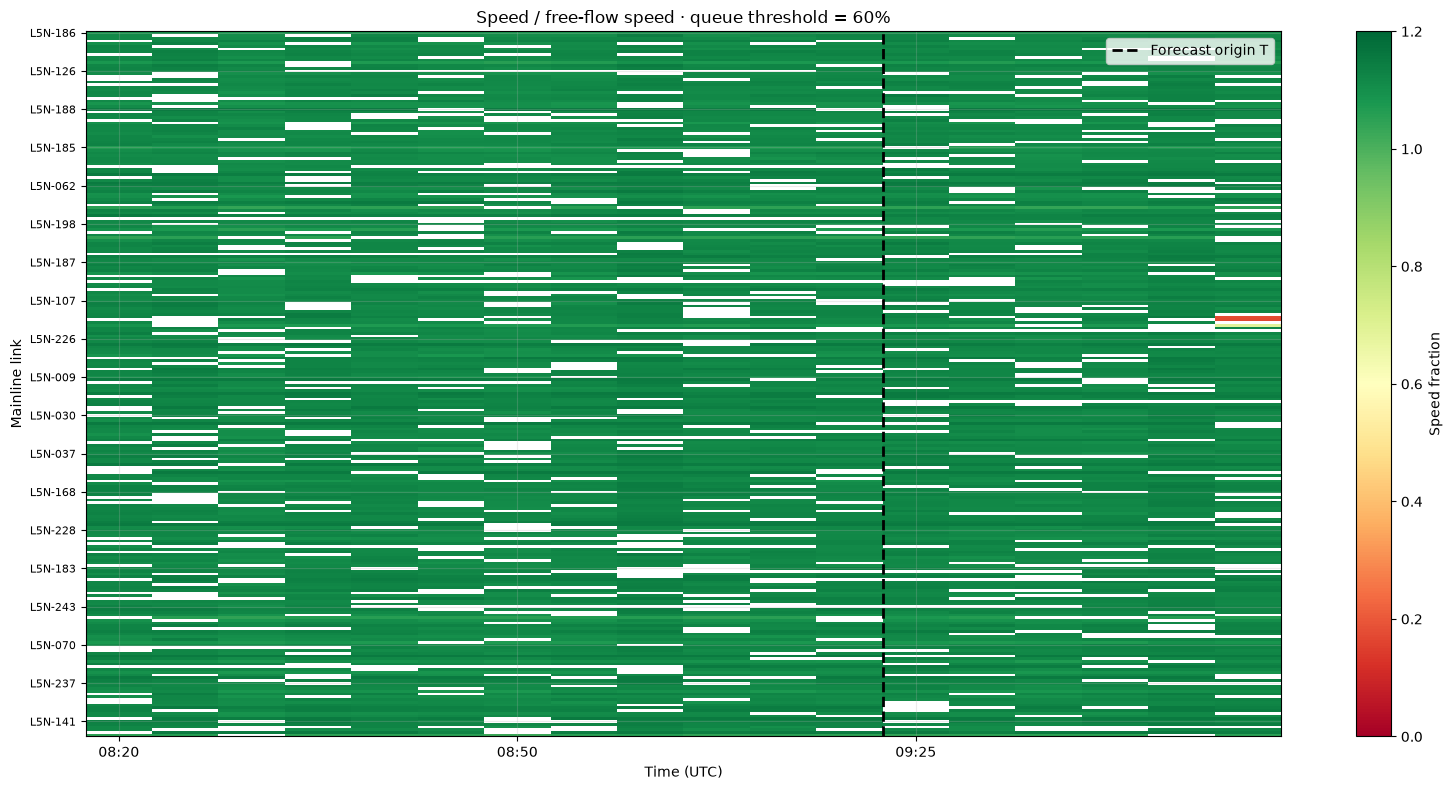

In [9]:
# Compare link-normalized speeds with the benchmark's queue threshold.
all_window = pl.concat([history, label_rows.join(links, left_on="link_id", right_on="mainline_link_id", how="left")], how="diagonal_relaxed")
all_window = all_window.with_columns((pl.col("speed_kmh") / pl.col("free_flow_speed_kmh")).alias("speed_fraction"))
window_all_times = sorted(all_window.get_column("timestamp").unique().to_list())
fraction_values = matrix_for(all_window, "speed_fraction", window_all_times)
fig, ax = plt.subplots(figsize=(16, 8))
image = ax.imshow(fraction_values, aspect="auto", interpolation="nearest", cmap="RdYlGn", vmin=0, vmax=1.2)
origin_index = window_all_times.index(origin) if origin in window_all_times else len(window_times) - 1
ax.axvline(origin_index + 0.5, color="black", linewidth=2, linestyle="--", label="Forecast origin T")
ax.axhline(-0.5, color="black", linewidth=0)
window_tick_positions = np.arange(0, len(window_links), max(1, len(window_links) // 18))
ax.set_yticks(window_tick_positions, labels=[window_links[i] for i in window_tick_positions], fontsize=8)
ax.set_xticks(np.arange(0, len(window_all_times), 6), labels=[window_all_times[i][11:16] for i in range(0, len(window_all_times), 6)])
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Mainline link")
ax.set_title(f"Speed / free-flow speed · queue threshold = {QUEUE_SPEED_FRACTION:.0%}")
fig.colorbar(image, ax=ax, label="Speed fraction")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 7. Onset versus ongoing windows

A final overview compares the training-window mix by condition and history coverage. Use it to see what the selected panel asks a Task 2 model to handle.


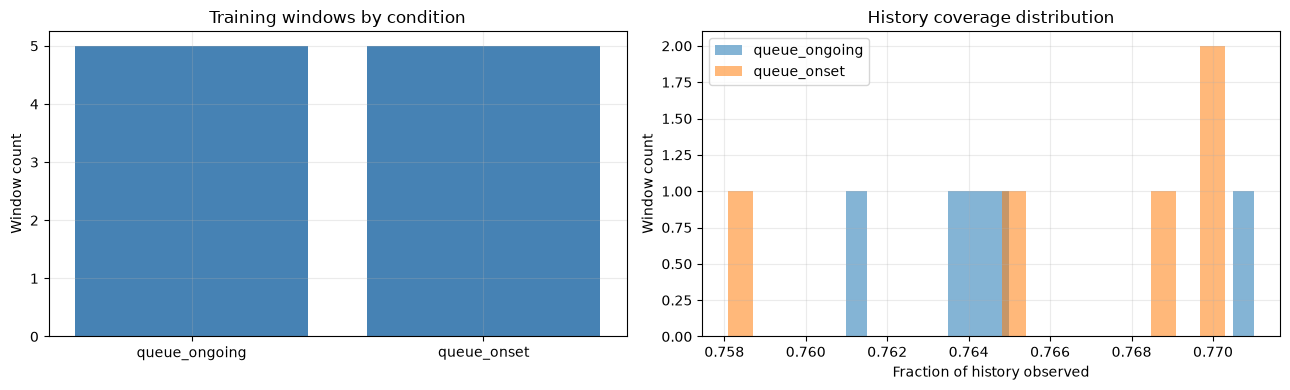

In [10]:
# Summarize the training-window distribution and history coverage.
window_index = window_index.with_columns(pl.col("history_coverage").cast(pl.Float64))
conditions = window_index.group_by("condition").agg(pl.len().alias("windows")).sort("condition")
coverage_by_condition = window_index.group_by("condition").agg(pl.col("history_coverage").mean().alias("mean_coverage")).sort("condition")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(conditions["condition"].to_list(), conditions["windows"].to_list(), color="steelblue")
axes[0].set_title("Training windows by condition")
axes[0].set_ylabel("Window count")
for condition in window_index.get_column("condition").unique().sort().to_list():
    values = window_index.filter(pl.col("condition") == condition)["history_coverage"].to_numpy()
    axes[1].hist(values, bins=20, alpha=0.55, label=condition)
axes[1].set_title("History coverage distribution")
axes[1].set_xlabel("Fraction of history observed")
axes[1].set_ylabel("Window count")
axes[1].legend()
plt.tight_layout()
plt.show()


## 8. Official Task 2 input histories across the released splits

Each panel shows the published forecast windows for one data split. Columns
are forecast windows in date order; rows are mainline links in upstream-to-
downstream network order. Each cell gives the fraction of the 60-minute input
history for that link where both speed and flow are present. The chart uses
released window histories and does not read validation or private answer
labels.


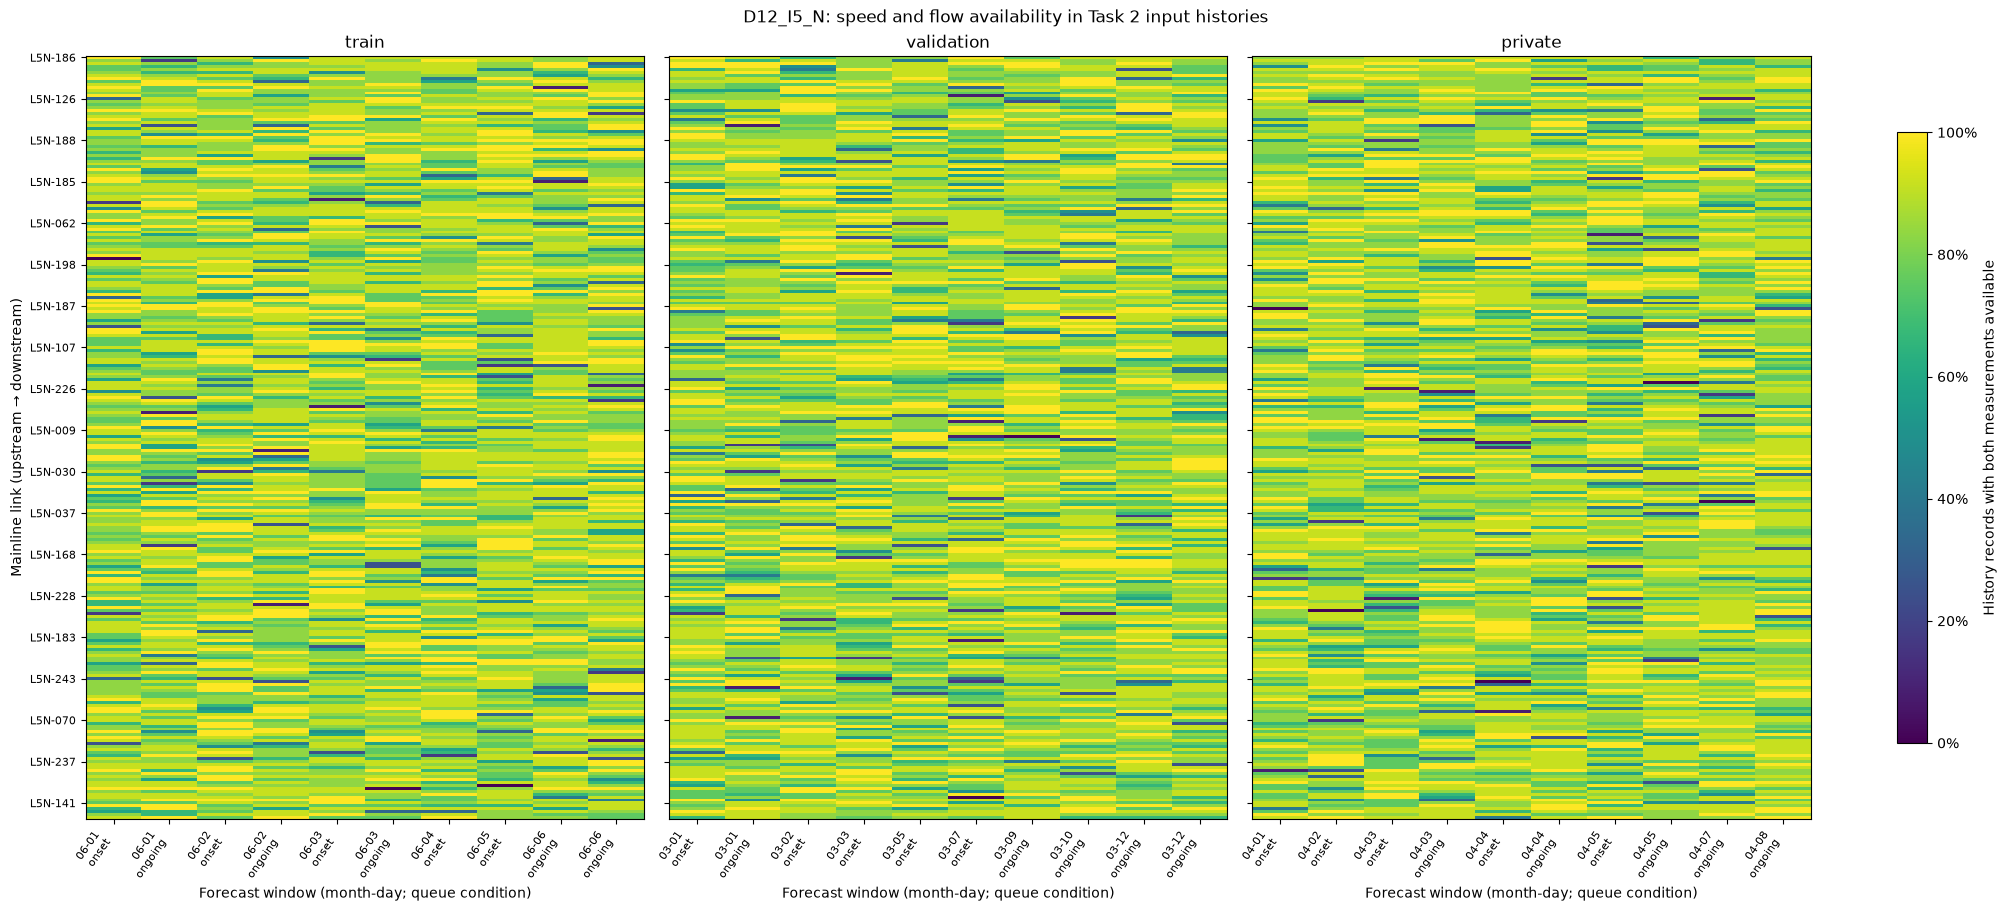

In [11]:
# Compare link-level measurement availability across the official Task 2 input histories.
from matplotlib.ticker import PercentFormatter

split_order = ["train", "validation", "private"]
condition_order = ["queue_onset", "queue_ongoing"]
window_indexes = {
    split_name: pl.read_csv(DATA_ROOT / "task2" / PANEL / split_name / "window_index.csv")
    for split_name in split_order
}
fig, axes = plt.subplots(1, len(split_order), figsize=(20, 9), sharey=True, layout="constrained")

for ax, split_name in zip(axes, split_order, strict=True):
    windows = window_indexes[split_name].sort(["forecast_origin", "condition"])
    window_ids = windows["window_id"].to_list()
    history = pl.read_parquet(DATA_ROOT / "task2" / PANEL / split_name / "window_history.parquet")
    link_history_coverage = (
        history.group_by("window_id", "link_id")
        .agg(
            (
                pl.col("speed_kmh").is_not_null()
                & pl.col("flow_vph").is_not_null()
            ).cast(pl.Float64).mean().alias("visible_fraction")
        )
    )
    coverage_by_window_and_link = (
        link_history_coverage.pivot(on="window_id", index="link_id", values="visible_fraction")
        .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id", how="right")
        .sort("order_index")
        .select(window_ids)
        .fill_null(0)
        .to_numpy()
    )
    image = ax.imshow(
        coverage_by_window_and_link,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )
    labels = [
        f"{row['forecast_origin'][5:10]}\n{row['condition'].replace('queue_', '')}"
        for row in windows.iter_rows(named=True)
    ]
    ax.set_xticks(np.arange(len(window_ids)), labels=labels, rotation=55, ha="right", fontsize=8)
    ax.set_title(split_name)
    ax.set_xlabel("Forecast window (month-day; queue condition)")
    ax.grid(False)

link_order = links.sort("order_index")["mainline_link_id"].to_list()
link_tick_positions = np.arange(0, len(link_order), max(1, len(link_order) // 18))
axes[0].set_yticks(link_tick_positions, labels=[link_order[i] for i in link_tick_positions], fontsize=8)
axes[0].set_ylabel("Mainline link (upstream → downstream)")
fig.suptitle(f"{PANEL}: speed and flow availability in Task 2 input histories")
fig.colorbar(
    image,
    ax=axes,
    location="right",
    label="History records with both measurements available",
    shrink=0.8,
    format=PercentFormatter(xmax=1),
)
plt.show()


## 9. Which links are visible at T+30?

Task 2 asks for predictions through 30 minutes after forecast origin `T`.
This heatmap shows, for each training queue-onset window, whether the masked
release contains both speed and flow for each mainline link at `T+30`. A value
of one means both measurements are visible; a value of zero means at least one
is masked. Validation and private `T+30` values are withheld as evaluation
labels, so those splits have no visible target measurements to plot. This
check uses only masked inputs and does not read answer labels.


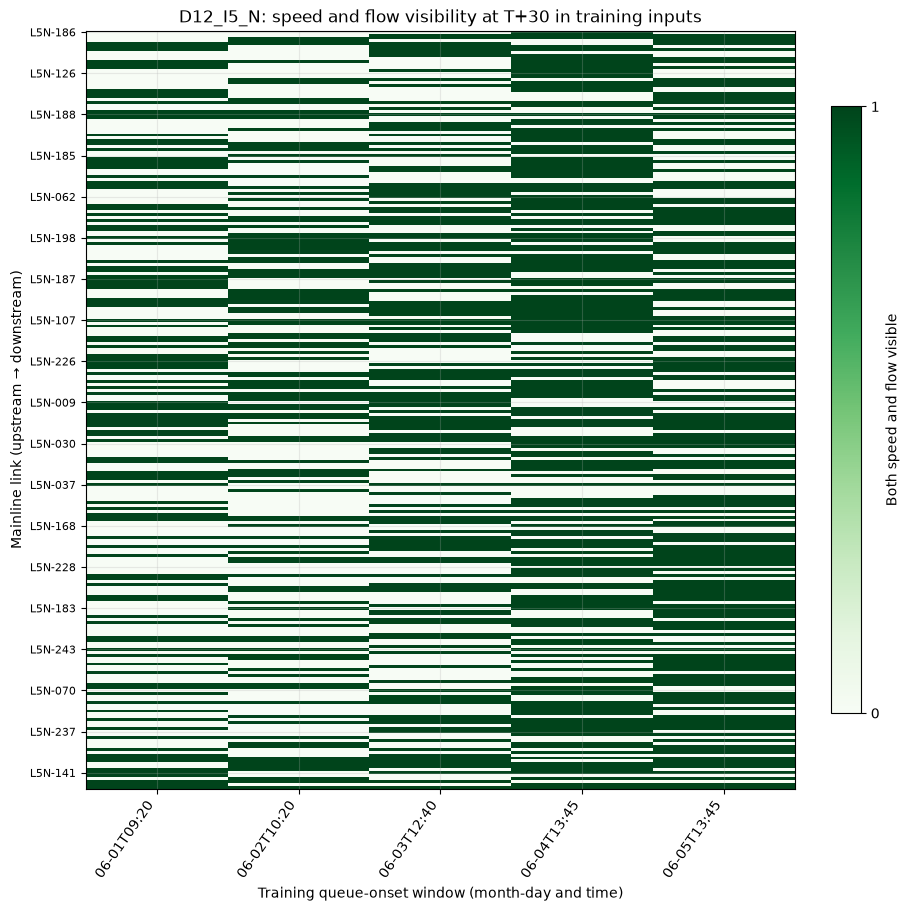

In [12]:
# Show link-level visibility at T+30 for training windows using masked inputs only.
from datetime import datetime, timedelta

train_onset_windows = (
    window_indexes["train"]
    .filter(pl.col("condition") == "queue_onset")
    .sort("forecast_origin")
)
train_window_rows = list(train_onset_windows.iter_rows(named=True))
forecast_targets = pl.DataFrame(
    {
        "window_id": [row["window_id"] for row in train_window_rows],
        "timestamp": [
            (datetime.fromisoformat(row["forecast_origin"].replace("Z", "+00:00")) + timedelta(minutes=30))
            .strftime("%Y-%m-%dT%H:%M:%SZ")
            for row in train_window_rows
        ],
    }
)
target_dates = sorted({timestamp[:10] for timestamp in forecast_targets["timestamp"].to_list()})
masked_glob = str(DATA_ROOT / "corridors" / PANEL / "train" / "mainline_states_masked" / "**" / "*.parquet")
masked_targets = (
    pl.scan_parquet(masked_glob, hive_partitioning=True)
    .filter(
        pl.col("date").is_in(target_dates)
        & pl.col("timestamp").is_in(forecast_targets["timestamp"].to_list())
    )
    .select("timestamp", "link_id", "speed_kmh", "flow_vph")
    .collect()
    .join(forecast_targets, on="timestamp", how="inner")
)
visible_by_window_and_link = (
    masked_targets.group_by("window_id", "link_id")
    .agg(
        (
            pl.col("speed_kmh").is_not_null()
            & pl.col("flow_vph").is_not_null()
        ).cast(pl.Float64).mean().alias("both_measurements_visible")
    )
)
window_ids = train_onset_windows["window_id"].to_list()
visibility_by_link_and_window = (
    visible_by_window_and_link.pivot(on="window_id", index="link_id", values="both_measurements_visible")
    .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id", how="right")
    .sort("order_index")
    .select(window_ids)
    .fill_null(0)
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(9, 9), layout="constrained")
image = ax.imshow(
    visibility_by_link_and_window,
    aspect="auto",
    interpolation="nearest",
    cmap="Greens",
    vmin=0,
    vmax=1,
)
ax.set_xticks(
    np.arange(len(window_ids)),
    labels=[row["forecast_origin"][5:16] for row in train_window_rows],
    rotation=55,
    ha="right",
)
link_order = links.sort("order_index")["mainline_link_id"].to_list()
link_tick_positions = np.arange(0, len(link_order), max(1, len(link_order) // 18))
ax.set_yticks(link_tick_positions, labels=[link_order[i] for i in link_tick_positions], fontsize=8)
ax.set_xlabel("Training queue-onset window (month-day and time)")
ax.set_ylabel("Mainline link (upstream → downstream)")
ax.set_title(f"{PANEL}: speed and flow visibility at T+30 in training inputs")
fig.colorbar(image, ax=ax, ticks=[0, 1], label="Both speed and flow visible", shrink=0.8)
plt.show()


## 10. Task 1: compare mask regimes

Each training date belongs to one mask regime. This samples one day from each regime and compares the observed fraction and the spatial pattern of visible cells. The first chart indicates how much information remains; the three heatmaps show whether missingness is scattered or clustered.


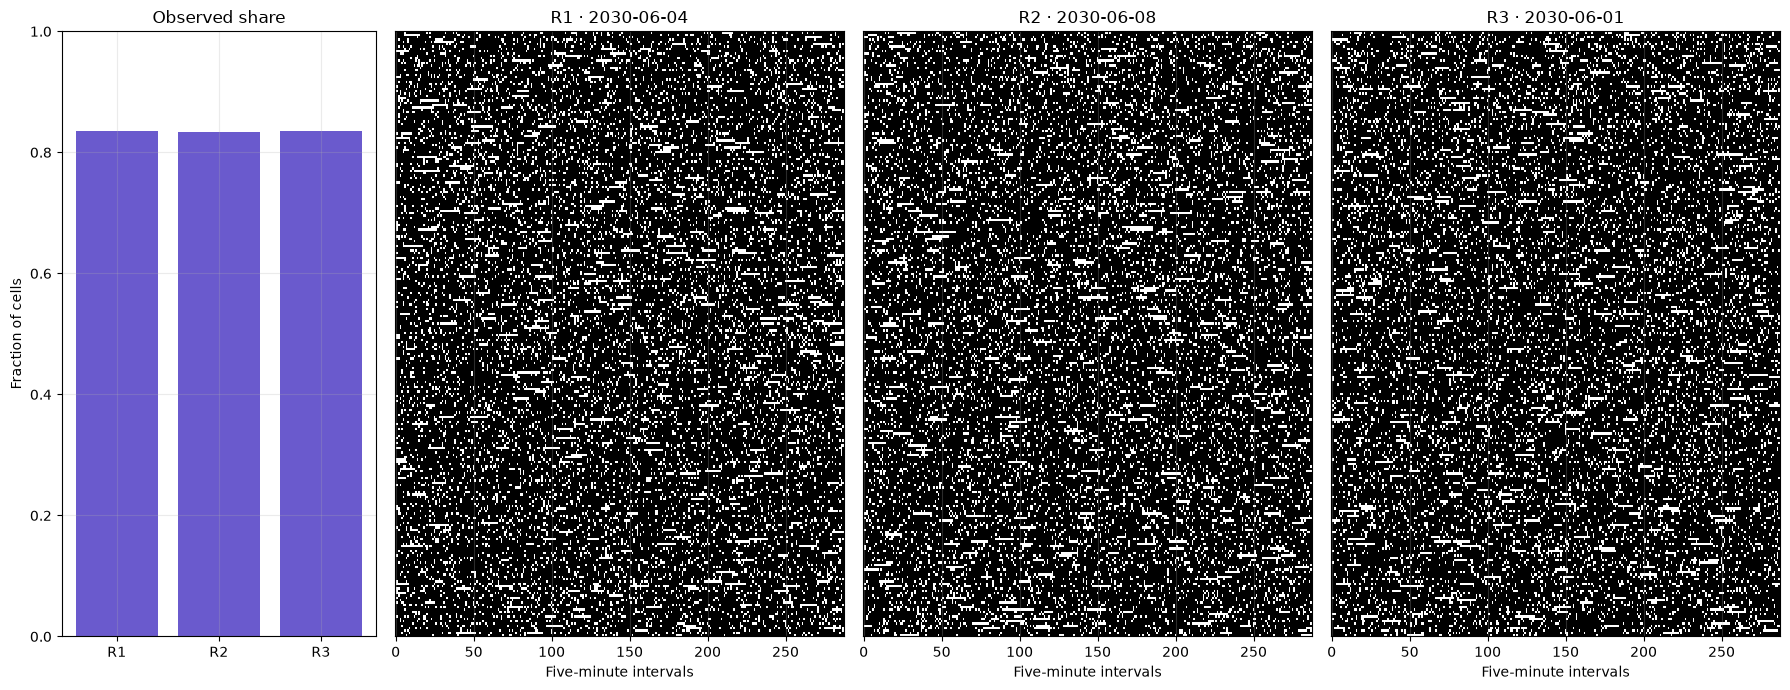

In [13]:
# Read one released day from each mask partition without scanning every date.
masked_root = train_root / "mainline_states_masked"
regime_examples = []
for regime_directory in sorted(masked_root.glob("mask_regime=*")):
    regime_files = sorted(regime_directory.glob("*.parquet"))
    if regime_files:
        regime_examples.append(pl.read_parquet(regime_files[0]))
regime_sample = pl.concat(regime_examples).join(
    links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"),
    on="link_id",
    how="left",
)
regime_summary = (
    regime_sample.group_by("mask_regime")
    .agg(pl.col("is_observed").mean().alias("observed_fraction"), pl.col("date").first().alias("sample_date"))
    .sort("mask_regime")
)

fig, axes = plt.subplots(1, 4, figsize=(18, 7), gridspec_kw={"width_ratios": [0.7, 1, 1, 1]})
axes[0].bar(regime_summary["mask_regime"].to_list(), regime_summary["observed_fraction"].to_list(), color="slateblue")
axes[0].set_ylim(0, 1)
axes[0].set_title("Observed share")
axes[0].set_ylabel("Fraction of cells")
for ax, regime in zip(axes[1:], regime_summary["mask_regime"].to_list()):
    sample = regime_sample.filter(pl.col("mask_regime") == regime)
    sample_times = sorted(sample.get_column("timestamp").unique().to_list())
    matrix = (
        sample.pivot(on="timestamp", index="link_id", values="is_observed", aggregate_function="max")
        .select("link_id", *sample_times)
        .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id")
        .sort("order_index")
        .select(sample_times)
        .to_numpy()
    )
    ax.imshow(matrix, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"{regime} · {sample.get_column('date').first()}")
    ax.set_xlabel("Five-minute intervals")
    ax.set_yticks([])
plt.tight_layout()
plt.show()


## 11. Ramp counts and detector quality

Ramp loops measure entering and exiting demand, not mainline speed. Their flow and availability can provide useful context for a queue forecast or physics check. Lines show the median eligible flow for each ramp type; the second panel shows how many ramp detectors contributed at each time.


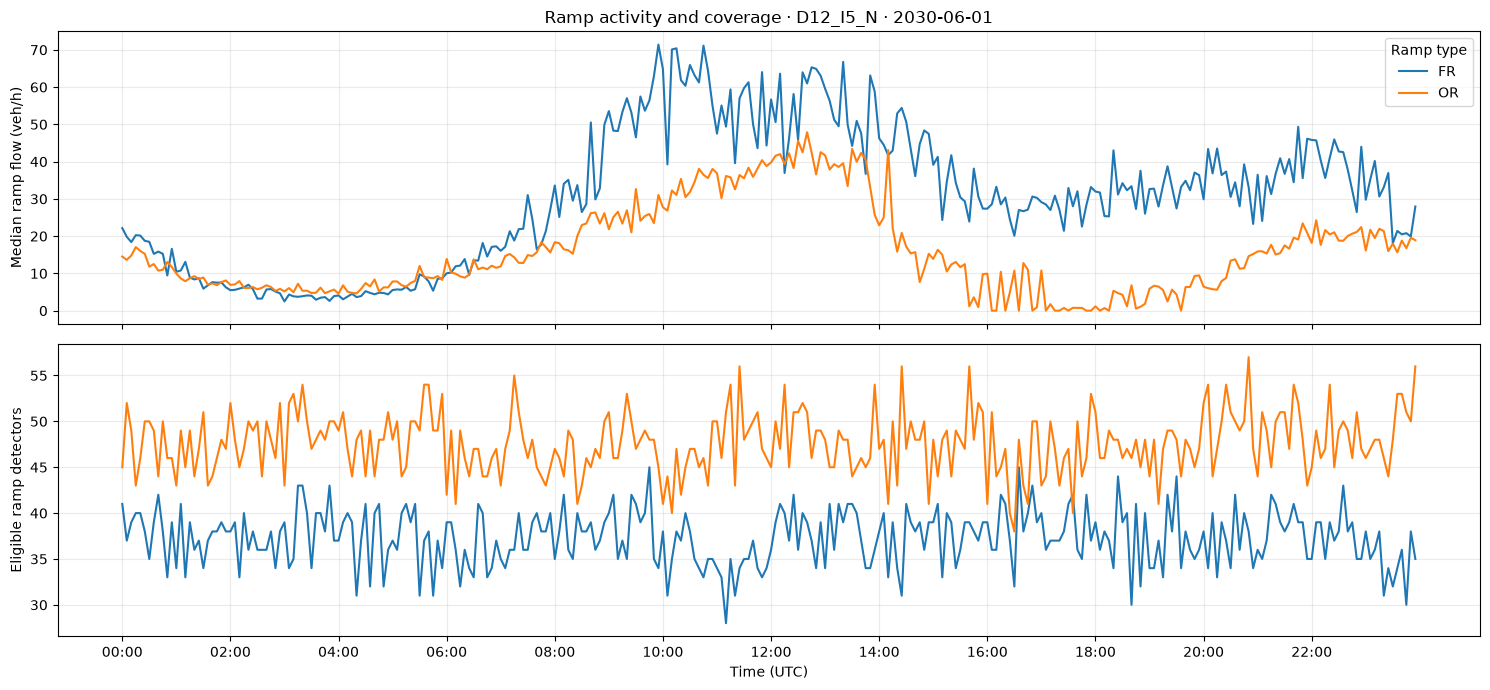

In [14]:
# Aggregate the chosen day's ramp series while keeping unavailable readings out of the flow summary.
ramp_glob = str(train_root / "ramp_states" / "**" / "*.parquet")
ramp_day = pl.scan_parquet(ramp_glob, hive_partitioning=True).filter(pl.col("date") == EXAMPLE_DATE).collect()
ramp_summary = (
    ramp_day.group_by(["timestamp", "ramp_type"])
    .agg(
        pl.col("flow_vph").filter(pl.col("is_score_eligible") == 1).median().alias("median_flow_vph"),
        pl.col("is_score_eligible").sum().alias("eligible_detectors"),
    )
    .sort("timestamp")
)
ramp_times = sorted(ramp_summary.get_column("timestamp").unique().to_list())
ramp_time_positions = {timestamp: position for position, timestamp in enumerate(ramp_times)}
ramp_tick_positions = np.arange(0, len(ramp_times), 24)
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ramp_type in sorted(ramp_summary.get_column("ramp_type").unique().to_list()):
    type_rows = ramp_summary.filter(pl.col("ramp_type") == ramp_type).sort("timestamp")
    time_positions = [ramp_time_positions[timestamp] for timestamp in type_rows["timestamp"]]
    axes[0].plot(time_positions, type_rows["median_flow_vph"].to_numpy(), label=ramp_type)
    axes[1].plot(time_positions, type_rows["eligible_detectors"].to_numpy(), label=ramp_type)
for ax in axes:
    ax.set_xticks(ramp_tick_positions, labels=[ramp_times[position][11:16] for position in ramp_tick_positions])
axes[0].set_ylabel("Median ramp flow (veh/h)")
axes[0].set_title(f"Ramp activity and coverage · {PANEL} · {EXAMPLE_DATE}")
axes[0].legend(title="Ramp type")
axes[1].set_ylabel("Eligible ramp detectors")
axes[1].set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()


## 12. Task 3: observed flow against the fundamental diagram

Task 3 rewards physically consistent state predictions. This view compares observed density and flow with the triangular fundamental diagrams supplied for a few links. A strong departure can be a real transient or measurement noise; the plot helps show where a purely data-driven estimate may conflict with the supplied physics.


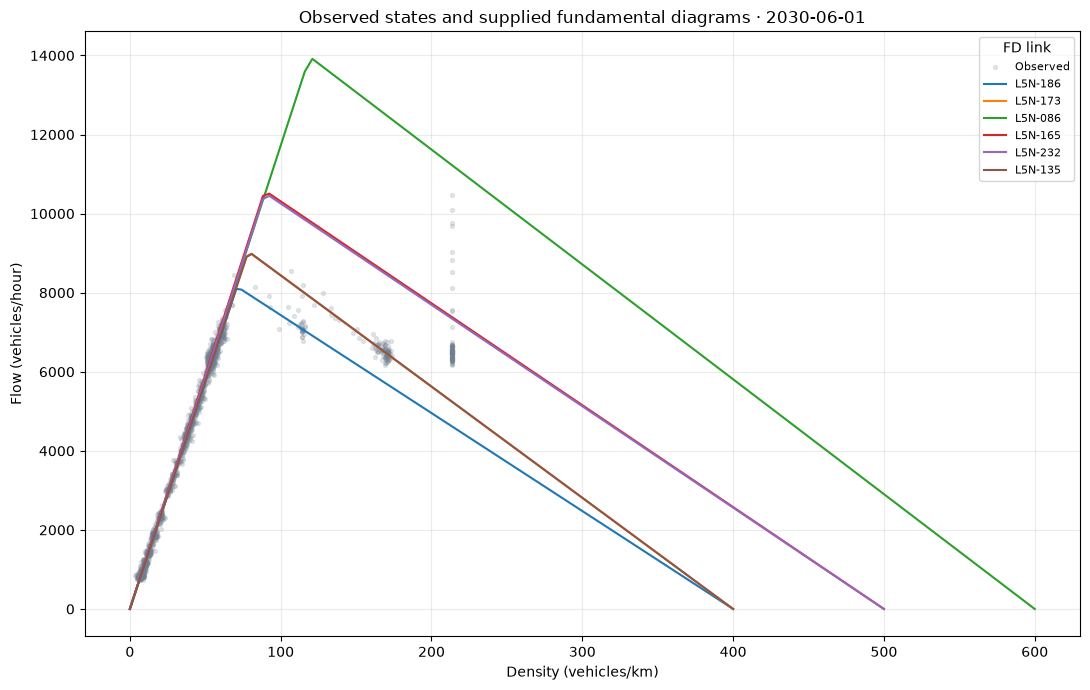

In [15]:
# Choose links across the corridor and overlay their supplied free-flow and congested branches.
fd_parameters = pl.read_csv(panel_root / "network" / "fd_parameters.csv").join(links, left_on="link_id", right_on="mainline_link_id", how="left").sort("order_index")
fd_step = max(1, fd_parameters.height // 6)
fd_examples = fd_parameters.gather_every(fd_step).head(6)
fd_observations = day.join(fd_examples.select("link_id"), on="link_id", how="inner").drop_nulls(["density_occ_linear_vehpkm", "flow_vph"])
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(fd_observations["density_occ_linear_vehpkm"], fd_observations["flow_vph"], s=8, alpha=0.18, color="slategray", label="Observed")
for row in fd_examples.iter_rows(named=True):
    density = np.linspace(0, row["k_jam"], 120)
    congested_branch = row["capacity_vph"] * (row["k_jam"] - density) / (row["k_jam"] - row["critical_density"])
    flow_curve = np.where(density <= row["critical_density"], density * row["free_speed_kmh"], congested_branch)
    ax.plot(density, flow_curve, linewidth=1.5, label=row["link_id"])
ax.set_xlabel("Density (vehicles/km)")
ax.set_ylabel("Flow (vehicles/hour)")
ax.set_title(f"Observed states and supplied fundamental diagrams · {EXAMPLE_DATE}")
ax.legend(title="FD link", fontsize=8)
plt.tight_layout()
plt.show()


## 13. Task 4: do the weak path priors explain link counts?

Task 4 provides path-level weak priors and link-level counts. Multiplying the prior path flows by the path-link incidence table gives the link counts implied by that prior. Agreement indicates where the prior is already informative; large gaps identify where a constrained OD/path-flow fit has work to do. The incidence heatmap shows how sampled paths share mainline links. This is a diagnostic, not the hidden path-flow answer.


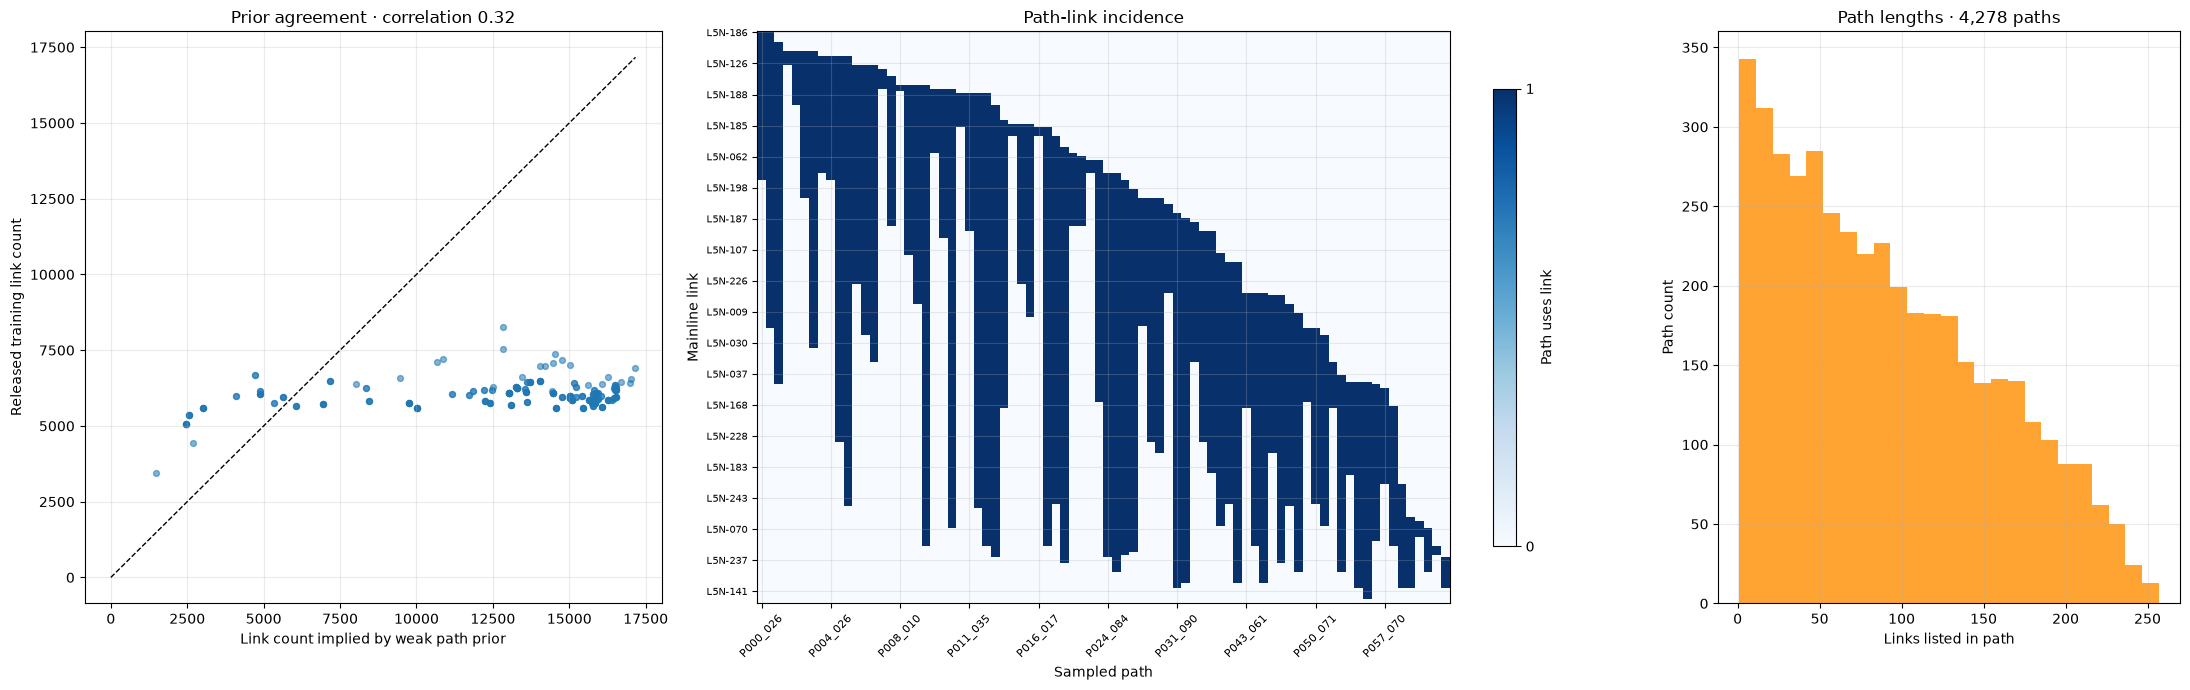

In [16]:
# Compare observed training link counts with the counts implied by the weak path prior.
task4_root = DATA_ROOT / "task4" / PANEL / SPLIT
path_incidence = pl.read_csv(panel_root / "network" / "path_link_incidence.csv")
weak_prior = pl.read_csv(task4_root / "synthetic_weak_prior.csv").select("path_id", "path_flow")
link_counts = pl.read_csv(task4_root / "synthetic_link_counts.csv").select("link_id", "count")
implied_counts = (
    path_incidence.join(weak_prior, on="path_id", how="inner")
    .group_by("link_id")
    .agg(pl.col("path_flow").sum().alias("prior_implied_count"))
)
count_comparison = link_counts.join(implied_counts, on="link_id", how="inner")
observed_counts = count_comparison["count"].to_numpy()
prior_counts = count_comparison["prior_implied_count"].to_numpy()
count_correlation = np.corrcoef(observed_counts, prior_counts)[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 1.5, 0.8]})
axes[0].scatter(prior_counts, observed_counts, alpha=0.55, s=18)
count_limit = max(float(observed_counts.max()), float(prior_counts.max()))
axes[0].plot([0, count_limit], [0, count_limit], color="black", linestyle="--", linewidth=1)
axes[0].set_xlabel("Link count implied by weak path prior")
axes[0].set_ylabel("Released training link count")
axes[0].set_title(f"Prior agreement · correlation {count_correlation:.2f}")
path_set = pl.read_csv(panel_root / "network" / "path_set.csv")
path_lengths = path_set.with_columns(
    pl.col("link_seq").str.split(";").list.len().alias("mainline_links_per_path")
)
selected_paths = path_set.sample(n=min(80, path_set.height), seed=7).sort("path_id")["path_id"].to_list()
incidence_sample = (
    path_incidence.filter(pl.col("path_id").is_in(selected_paths))
    .with_columns(pl.lit(1).alias("included"))
    .pivot(on="path_id", index="link_id", values="included", aggregate_function="max")
)
incidence_columns = [path_id for path_id in selected_paths if path_id in incidence_sample.columns]
incidence_matrix = (
    incidence_sample.select("link_id", *incidence_columns)
    .join(links.select(pl.col("mainline_link_id").alias("link_id"), "order_index"), on="link_id", how="right")
    .sort("order_index")
    .select(incidence_columns)
    .fill_null(0)
    .to_numpy()
)
incidence_image = axes[1].imshow(incidence_matrix, aspect="auto", interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
path_tick_positions = np.arange(0, len(incidence_columns), max(1, len(incidence_columns) // 10))
axes[1].set_xticks(path_tick_positions, labels=[incidence_columns[i] for i in path_tick_positions], rotation=45, fontsize=8)
axes[1].set_yticks(link_tick_positions, labels=[link_order[i] for i in link_tick_positions], fontsize=7)
axes[1].set_xlabel("Sampled path")
axes[1].set_ylabel("Mainline link")
axes[1].set_title("Path-link incidence")
fig.colorbar(incidence_image, ax=axes[1], ticks=[0, 1], label="Path uses link", shrink=0.8)
axes[2].hist(path_lengths["mainline_links_per_path"].to_numpy(), bins=25, color="darkorange", alpha=0.8)
axes[2].set_xlabel("Links listed in path")
axes[2].set_ylabel("Path count")
axes[2].set_title(f"Path lengths · {path_lengths.height:,} paths")
plt.tight_layout()
plt.show()


## 14. How different are the panels?

The network and task templates vary by corridor. These summaries help decide whether shared features and models are reasonable, and they make exceptions visible (for example, panels without Task 2 windows). Path counts use the supplied path sets; Task 2 counts use the training window index.


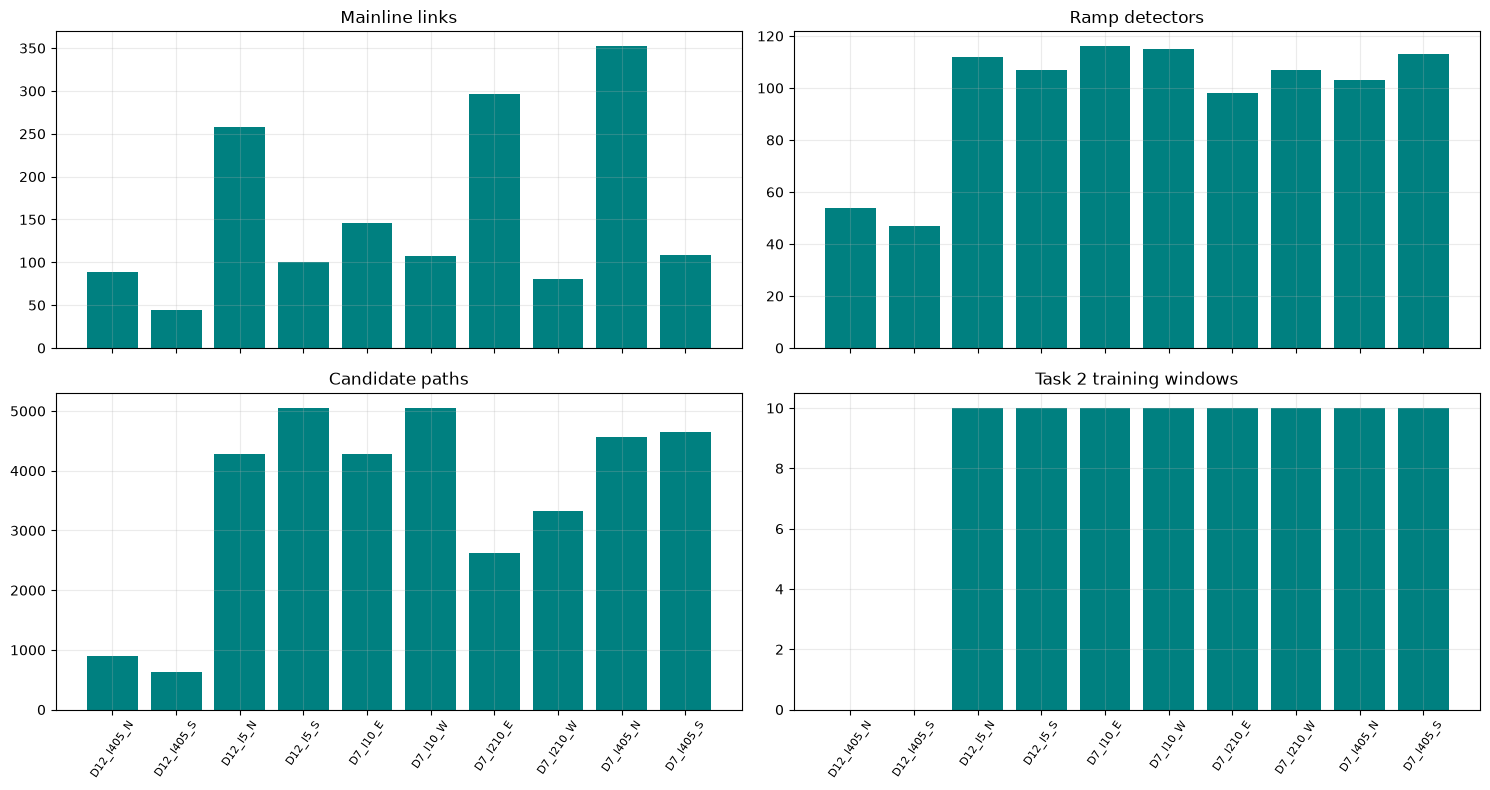

shape: (10, 6)
┌────────────┬────────────────┬───────┬───────┬──────────┬───────────────┐
│ panel      ┆ mainline_links ┆ ramps ┆ paths ┆ OD_pairs ┆ task2_windows │
│ ---        ┆ ---            ┆ ---   ┆ ---   ┆ ---      ┆ ---           │
│ str        ┆ i64            ┆ i64   ┆ i64   ┆ i64      ┆ i64           │
╞════════════╪════════════════╪═══════╪═══════╪══════════╪═══════════════╡
│ D12_I405_N ┆ 89             ┆ 54    ┆ 903   ┆ 903      ┆ 0             │
│ D12_I405_S ┆ 44             ┆ 47    ┆ 630   ┆ 630      ┆ 0             │
│ D12_I5_N   ┆ 258            ┆ 112   ┆ 4278  ┆ 4278     ┆ 10            │
│ D12_I5_S   ┆ 100            ┆ 107   ┆ 5050  ┆ 5050     ┆ 10            │
│ D7_I10_E   ┆ 146            ┆ 116   ┆ 4278  ┆ 4278     ┆ 10            │
│ D7_I10_W   ┆ 107            ┆ 115   ┆ 5050  ┆ 5050     ┆ 10            │
│ D7_I210_E  ┆ 297            ┆ 98    ┆ 2628  ┆ 2628     ┆ 10            │
│ D7_I210_W  ┆ 81             ┆ 107   ┆ 3321  ┆ 3321     ┆ 10            │
│ D7_I405_

In [17]:
# Summarize the network and training example size for every released panel.
panel_summaries = []
for candidate_root in sorted((DATA_ROOT / "corridors").iterdir()):
    if not candidate_root.is_dir():
        continue
    candidate = candidate_root.name
    candidate_network = candidate_root / "network"
    candidate_task2 = DATA_ROOT / "task2" / candidate / "train" / "window_index.csv"
    candidate_paths = pl.read_csv(candidate_network / "path_set.csv")
    candidate_ramps = pl.read_csv(candidate_network / "ramp_attachment_map.csv")
    candidate_topology = pl.read_csv(candidate_network / "lwr_mainline_topology.csv")
    task2_windows = pl.read_csv(candidate_task2).height if candidate_task2.exists() else 0
    panel_summaries.append({
        "panel": candidate,
        "mainline_links": candidate_topology.height,
        "ramps": candidate_ramps.height,
        "paths": candidate_paths.height,
        "OD_pairs": candidate_paths.select(pl.struct("origin_zone", "destination_zone").n_unique()).item(),
        "task2_windows": task2_windows,
    })
panel_summary = pl.DataFrame(panel_summaries).sort("panel")

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, metric, title in zip(axes.flat, ("mainline_links", "ramps", "paths", "task2_windows"), ("Mainline links", "Ramp detectors", "Candidate paths", "Task 2 training windows")):
    ax.bar(panel_summary["panel"].to_list(), panel_summary[metric].to_list(), color="teal")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=55, labelsize=8)
plt.tight_layout()
plt.show()
print(panel_summary)


## Things to try

- Change `PANEL` and `EXAMPLE_DATE` to compare corridor structure and traffic patterns.
- Read the topology schematic upstream-to-downstream to connect link order with ramp attachments.
- Compare the published Task 2 window dates and check whether masked state values are visible at T+30.
- Read the topology schematic upstream-to-downstream to connect link order with ramp attachments.
- Try a few `window_id` values from each condition to see how onset and ongoing queues differ.
- Compare the unmasked and masked views to understand which patterns are hidden from reconstruction models.
- Use the Task 2 history plot to reason about what is visible at forecast origin `T`; never use post-`T` evaluation data as model input.

The source files are documented in `kaggle_public/README.md` and the competition Data page.
